In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

#### Load data and remove duplicates and invalid rows

In [2]:
df = pd.read_csv("pha_dataset.csv")
print(df.shape)

C:\Users\HAI\AppData\Local\Temp\ipykernel_18456\4047954759.py:1: DtypeWarning: Columns (3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("pha_dataset.csv")


(958524, 45)


In [3]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  object 
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  object 
 3   pdes            958524 non-null  object 
 4   name            22064 non-null   object 
 5   prefix          18 non-null      object 
 6   neo             958520 non-null  object 
 7   pha             938603 non-null  object 
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  object 
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  object 
 17  e         

In [5]:
df.columns

Index(['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H',
       'diameter', 'albedo', 'diameter_sigma', 'orbit_id', 'epoch',
       'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w',
       'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld',
       'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w',
       'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'class',
       'rms'],
      dtype='object')

In [6]:
df.describe()

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
count,9.585240e+05,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,...,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.385980e+05,9.386020e+05,9.386020e+05,9.385980e+05,958522.000000
mean,3.810114e+06,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,...,1.982929e+01,1.168449e+00,5.310234e+00,1.370062e+06,1.369977e+06,2.131453e+01,5.060221e-02,4.312780e+08,8.525815e+04,0.561153
std,6.831541e+06,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,...,2.903785e+03,1.282231e+02,1.333381e+03,9.158996e+08,9.158991e+08,7.197034e+03,9.814953e+00,2.953046e+11,2.767681e+07,2.745700
min,2.000001e+06,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,...,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,0.000000
25%,2.239632e+06,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,...,1.462000e-07,6.095900e-06,3.619400e-05,5.755000e-05,2.573700e-05,2.340900e-08,2.768800e-09,1.110900e-04,1.794500e-05,0.518040
50%,2.479262e+06,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,...,2.271900e-07,8.688800e-06,6.642550e-05,1.047100e-04,4.900100e-05,4.359000e-08,4.638000e-09,2.230800e-04,3.501700e-05,0.566280
75%,3.752518e+06,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,...,6.583200e-07,1.591500e-05,1.609775e-04,3.114400e-04,1.718900e-04,1.196600e-07,1.124000e-08,8.139600e-04,9.775475e-05,0.613927
max,5.401723e+07,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,...,1.015000e+06,5.533000e+04,1.199100e+06,8.845100e+11,8.845100e+11,5.509700e+06,7.698800e+03,2.853100e+14,1.910700e+10,2686.600000


In [7]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
df = df.drop_duplicates(subset="id")   # each asteroid id should appear once

Duplicate rows: 0


In [8]:
# Drop unnecessary columns
df_class = df.drop(['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix','moid','q','equinox','orbit_id'],axis=1)

# Oultier treatment

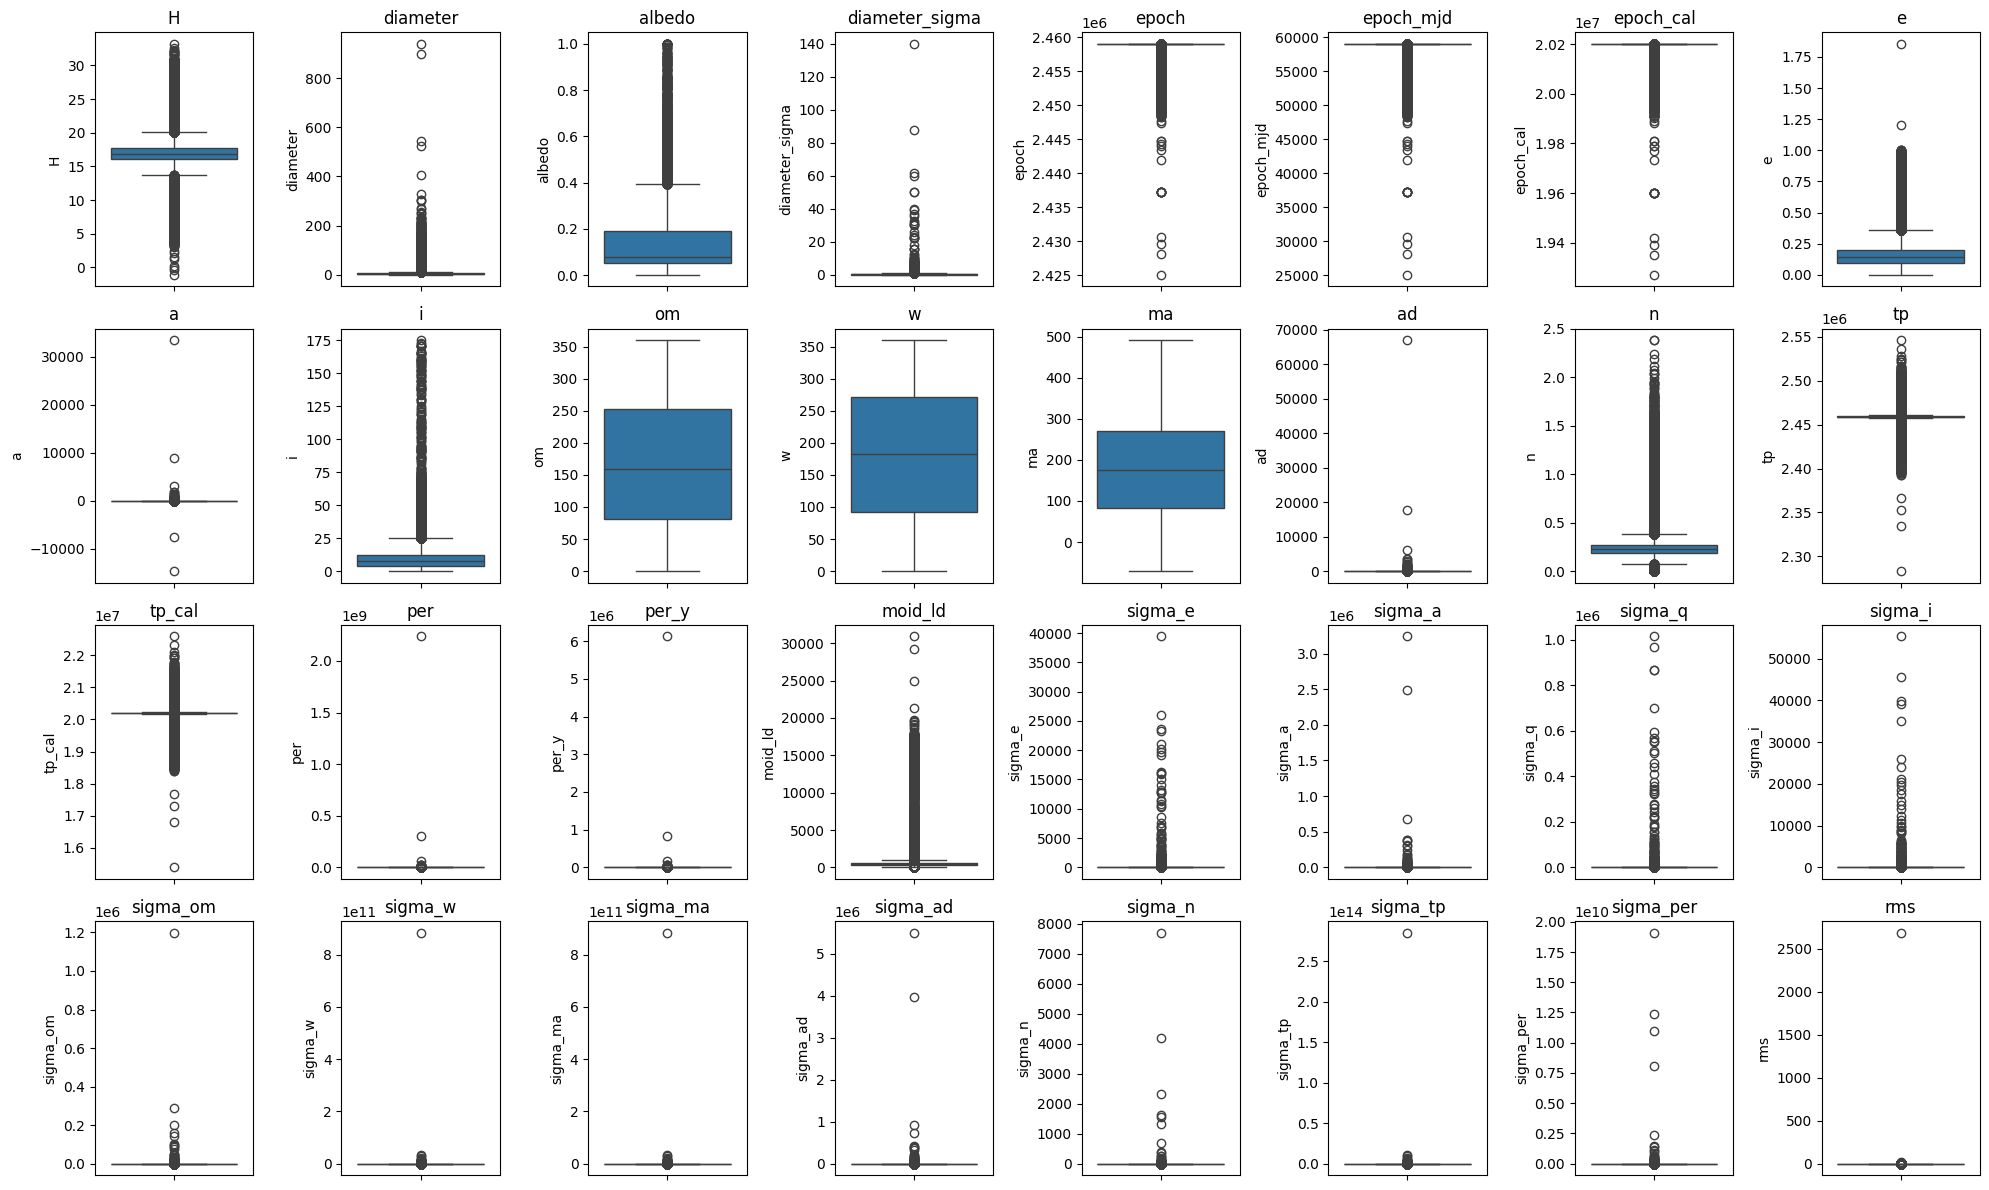

In [9]:
import seaborn as sns

num_cols = df_class.select_dtypes(include='number').columns.tolist()
fig, ax = plt.subplots(4, 8, figsize=(20, 12))

for i, col in enumerate(num_cols):
    row = i // 8
    col_idx = i % 8

    sns.boxplot(y=df_class[col], ax=ax[row, col_idx])
    ax[row, col_idx].set_title(col)

plt.tight_layout()
plt.show()

In [10]:
# Skewness before handling outliers
df_class[num_cols].skew()

H                   0.604709
diameter           25.852418
albedo              1.683567
diameter_sigma     69.824037
epoch              -6.858078
epoch_mjd          -6.858078
epoch_cal          -6.864155
e                   1.898895
a                 577.499553
i                   2.183736
om                  0.198256
w                  -0.020330
ma                  0.040664
ad                864.424060
n                   5.623457
tp                 -4.675623
tp_cal             -4.633673
per               953.004604
per_y             953.006095
moid_ld            15.745831
sigma_e           228.767223
sigma_a           627.861269
sigma_q           228.561124
sigma_i           264.274328
sigma_om          793.986974
sigma_w           959.728440
sigma_ma          959.729946
sigma_ad          660.965622
sigma_n           622.867836
sigma_tp          960.973697
sigma_per         538.581997
rms               976.736018
dtype: float64

#### Capping

In [11]:
import numpy as np

for col in num_cols:

    Q1 = df_class[col].quantile(0.25)  # 25th percentile
    Q3 = df_class[col].quantile(0.75)  # 75th percentile
    IQR = Q3 - Q1  # Interquartile range

    # Define lower and upper bound
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values at lower and upper bound
    df_class[col] = np.where(df_class[col] < lower_bound, lower_bound, df_class[col])
    df_class[col] = np.where(df_class[col] > upper_bound, upper_bound, df_class[col])

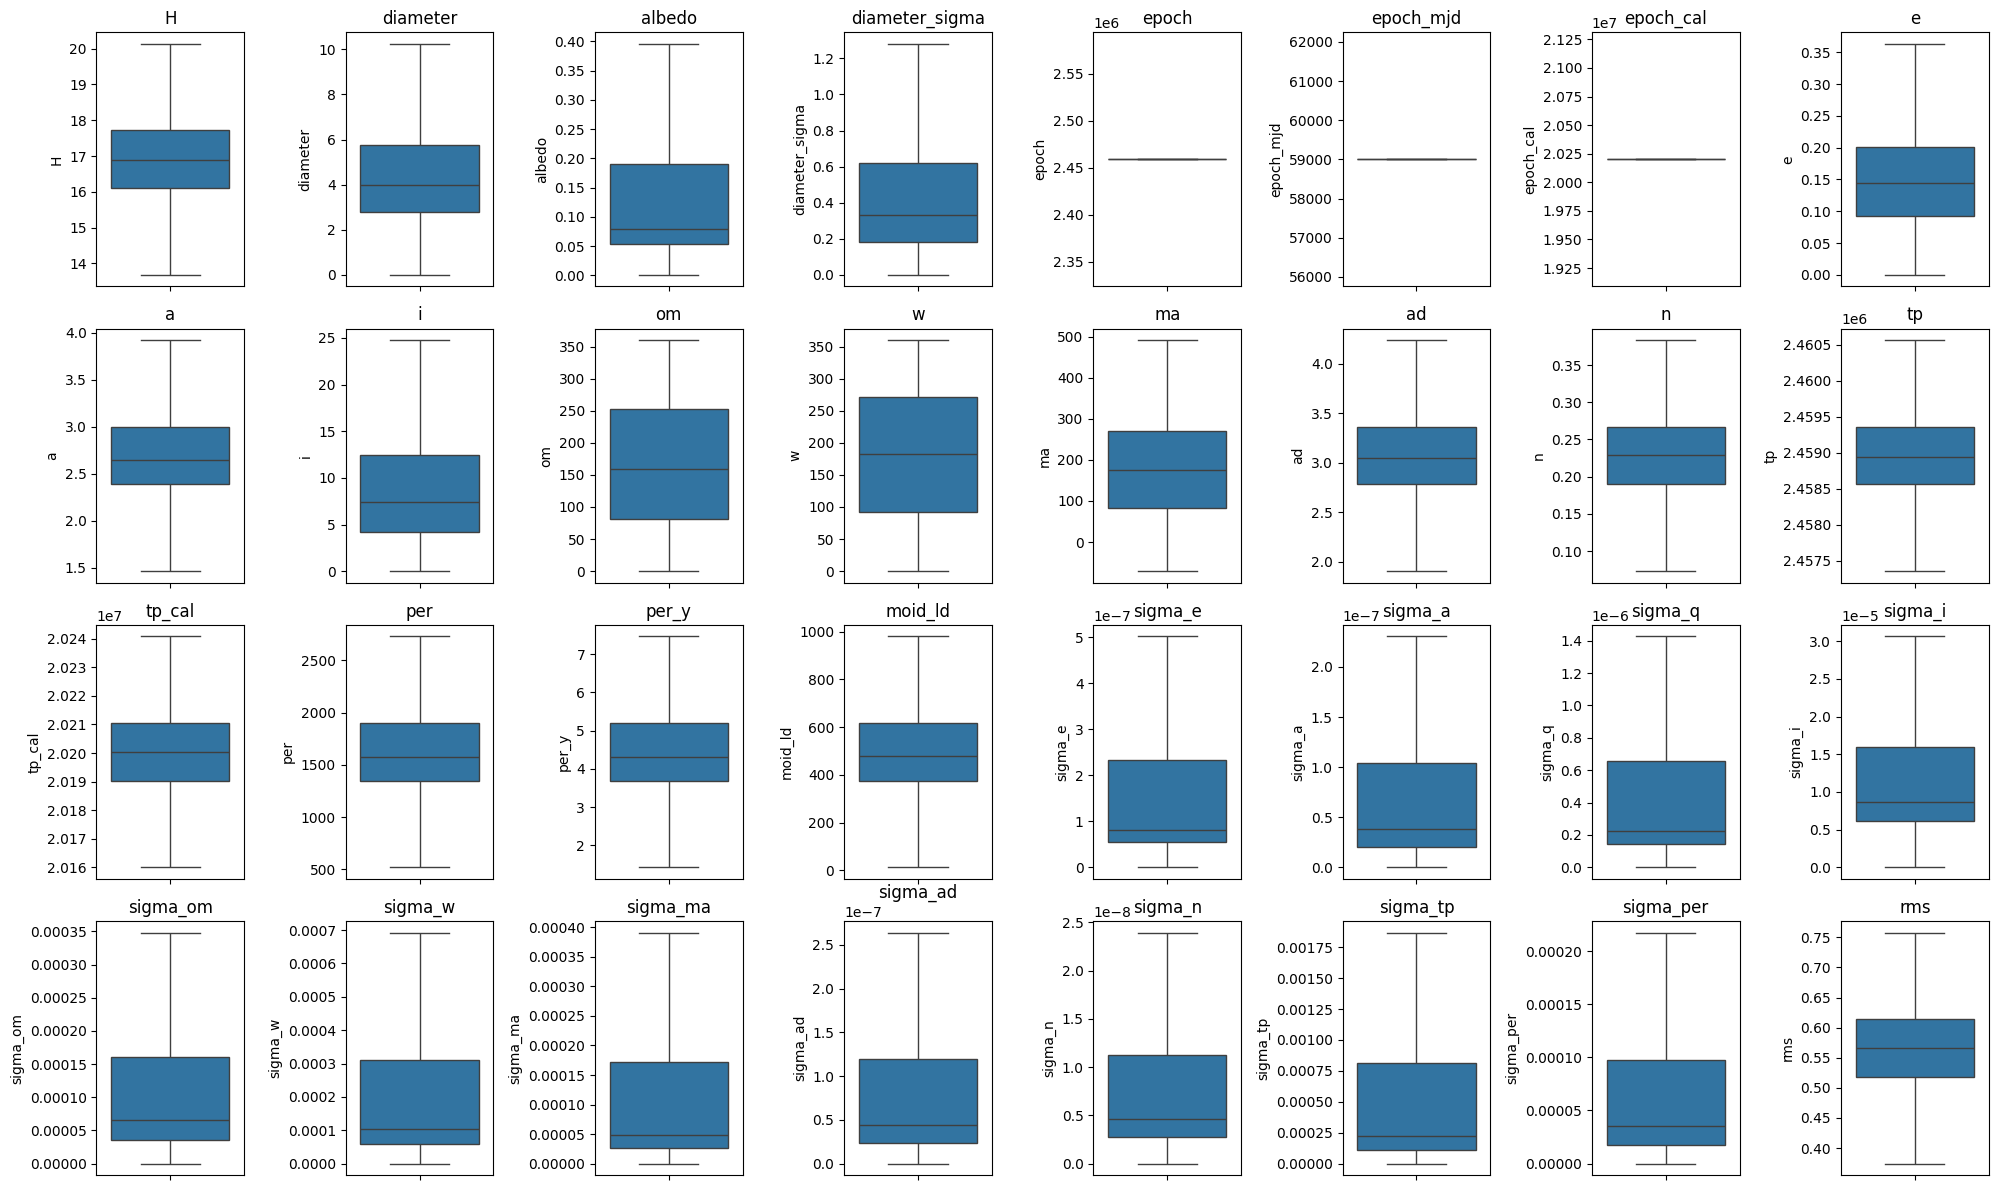

In [12]:
import seaborn as sns

num_cols = df_class.select_dtypes(include='number').columns.tolist()
fig, ax = plt.subplots(4, 8, figsize=(20, 12))

for i, col in enumerate(num_cols):
    row = i // 8
    col_idx = i % 8

    sns.boxplot(y=df_class[col], ax=ax[row, col_idx])
    ax[row, col_idx].set_title(col)

plt.tight_layout()
plt.show()

In [13]:
#Skewness after outlier treatment
df_class[num_cols].skew()

H                -0.088597
diameter          0.958134
albedo            1.156015
diameter_sigma    1.055152
epoch             0.000000
epoch_mjd         0.000000
epoch_cal         0.000000
e                 0.592488
a                 0.168974
i                 0.937240
om                0.198256
w                -0.020330
ma                0.040664
ad                0.167453
n                 0.489694
tp               -0.499144
tp_cal           -0.303355
per               0.283125
per_y             0.283048
moid_ld          -0.216831
sigma_e           0.000000
sigma_a           0.000000
sigma_q           1.126890
sigma_i           1.103445
sigma_om          1.152107
sigma_w           1.136071
sigma_ma          1.137255
sigma_ad          0.000000
sigma_n           0.000000
sigma_tp          1.140930
sigma_per         1.109039
rms              -0.257071
dtype: float64

In [14]:
df_class.columns

Index(['neo', 'pha', 'H', 'diameter', 'albedo', 'diameter_sigma', 'epoch',
       'epoch_mjd', 'epoch_cal', 'e', 'a', 'i', 'om', 'w', 'ma', 'ad', 'n',
       'tp', 'tp_cal', 'per', 'per_y', 'moid_ld', 'sigma_e', 'sigma_a',
       'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad',
       'sigma_n', 'sigma_tp', 'sigma_per', 'class', 'rms'],
      dtype='object')

In [15]:
df_class.isnull().sum()

neo                    4
pha                19921
H                   6263
diameter          822315
albedo            823421
diameter_sigma    822443
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid_ld              127
sigma_e            19922
sigma_a            19922
sigma_q            19922
sigma_i            19922
sigma_om           19922
sigma_w            19922
sigma_ma           19922
sigma_ad           19926
sigma_n            19922
sigma_tp           19922
sigma_per          19926
class                  0
rms                    2
dtype: int64

In [16]:
sigma_cols = [
    'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i',
    'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad',
    'sigma_n', 'sigma_tp', 'sigma_per'
]

df_class = df_class.drop(columns=sigma_cols)

In [17]:
df_class.isnull().sum()

neo                    4
pha                19921
H                   6263
diameter          822315
albedo            823421
diameter_sigma    822443
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid_ld              127
class                  0
rms                    2
dtype: int64

In [18]:
df_class.shape

(958524, 24)

In [19]:
df_class = df_class.dropna(subset='pha')

In [20]:
df_class.shape

(938603, 24)

In [21]:
df_class.isnull().sum()

neo                    4
pha                    0
H                   6262
diameter          802394
albedo            803500
diameter_sigma    802522
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid_ld                0
class                  0
rms                    1
dtype: int64

In [22]:
print(df_class['H'].isnull().sum())
print(df_class[['H', 'moid_ld', 'pha']].head())

6262
        H     moid_ld pha
0  13.679  620.640533   N
1  13.679  480.348639   N
2  13.679  402.514639   N
3  13.679  443.451432   N
4  13.679  426.433027   N


In [23]:
df_class['H'].isnull().sum() / len(df_class) * 100

np.float64(0.6671617286541807)

In [24]:
df_class = df_class.dropna(subset=['H']).copy()

In [25]:
drop_cols = ['diameter', 'albedo', 'diameter_sigma']

df_class = df_class.drop(columns=drop_cols)
df_class.isnull().sum()

neo          4
pha          0
H            0
epoch        0
epoch_mjd    0
epoch_cal    0
e            0
a            0
i            0
om           0
w            0
ma           1
ad           4
n            0
tp           0
tp_cal       0
per          4
per_y        1
moid_ld      0
class        0
rms          1
dtype: int64

In [26]:
df_class.isnull().sum()[df_class.isnull().sum() > 0]

neo      4
ma       1
ad       4
per      4
per_y    1
rms      1
dtype: int64

In [27]:
df_class[['neo', 'ma', 'ad', 'per', 'per_y', 'rms']].dtypes

neo       object
ma       float64
ad       float64
per      float64
per_y    float64
rms      float64
dtype: object

In [28]:
# Imputer
# 1. Categorical column
cat_imputer = SimpleImputer(strategy='most_frequent')
df_class[['neo']] = cat_imputer.fit_transform(df_class[['neo']])

# 2. Numerical columns
num_cols = ['ma', 'ad', 'per', 'per_y', 'rms']

num_imputer = SimpleImputer(strategy='median')
df_class[num_cols] = num_imputer.fit_transform(df_class[num_cols])

In [29]:
df_class.isnull().sum()

neo          0
pha          0
H            0
epoch        0
epoch_mjd    0
epoch_cal    0
e            0
a            0
i            0
om           0
w            0
ma           0
ad           0
n            0
tp           0
tp_cal       0
per          0
per_y        0
moid_ld      0
class        0
rms          0
dtype: int64

In [30]:
df_class.dtypes

neo           object
pha           object
H            float64
epoch        float64
epoch_mjd    float64
epoch_cal    float64
e            float64
a            float64
i            float64
om           float64
w            float64
ma           float64
ad           float64
n            float64
tp           float64
tp_cal       float64
per          float64
per_y        float64
moid_ld      float64
class         object
rms          float64
dtype: object

In [31]:
for col in df_class.select_dtypes(exclude="number").columns:
    print(f"{col}:",df_class[col].unique())

neo: ['N' 'Y']
pha: ['N' 'Y']
class: ['MBA' 'OMB' 'MCA' 'AMO' 'IMB' 'TJN' 'CEN' 'APO' 'ATE' 'AST' 'TNO' 'IEO'
 'HYA']


# Encoding

In [32]:
df_class['neo'] = df_class['neo'].map({'N': 0, 'Y': 1})

df_class['pha'] = df_class['pha'].map({'N': 0, 'Y': 1})

In [33]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded = ohe.fit_transform(df_class[['class']])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(['class']),
    index=df_class.index
)

df_class = pd.concat(
    [df_class.drop(columns=['class']), encoded_df],
    axis=1
)

In [36]:
df_class['pha'].value_counts()

pha
0    930275
1      2066
Name: count, dtype: int64

In [38]:
df_class.to_csv("pha_cleaned.csv",index=False)